--- RAW DATASET OVERVIEW ---
Dataset Shape: (891, 12)

First 5 Rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C1

/tmp/ipykernel_8290/1868050128.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)
/tmp/ipykernel_8290/1868050128.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', 

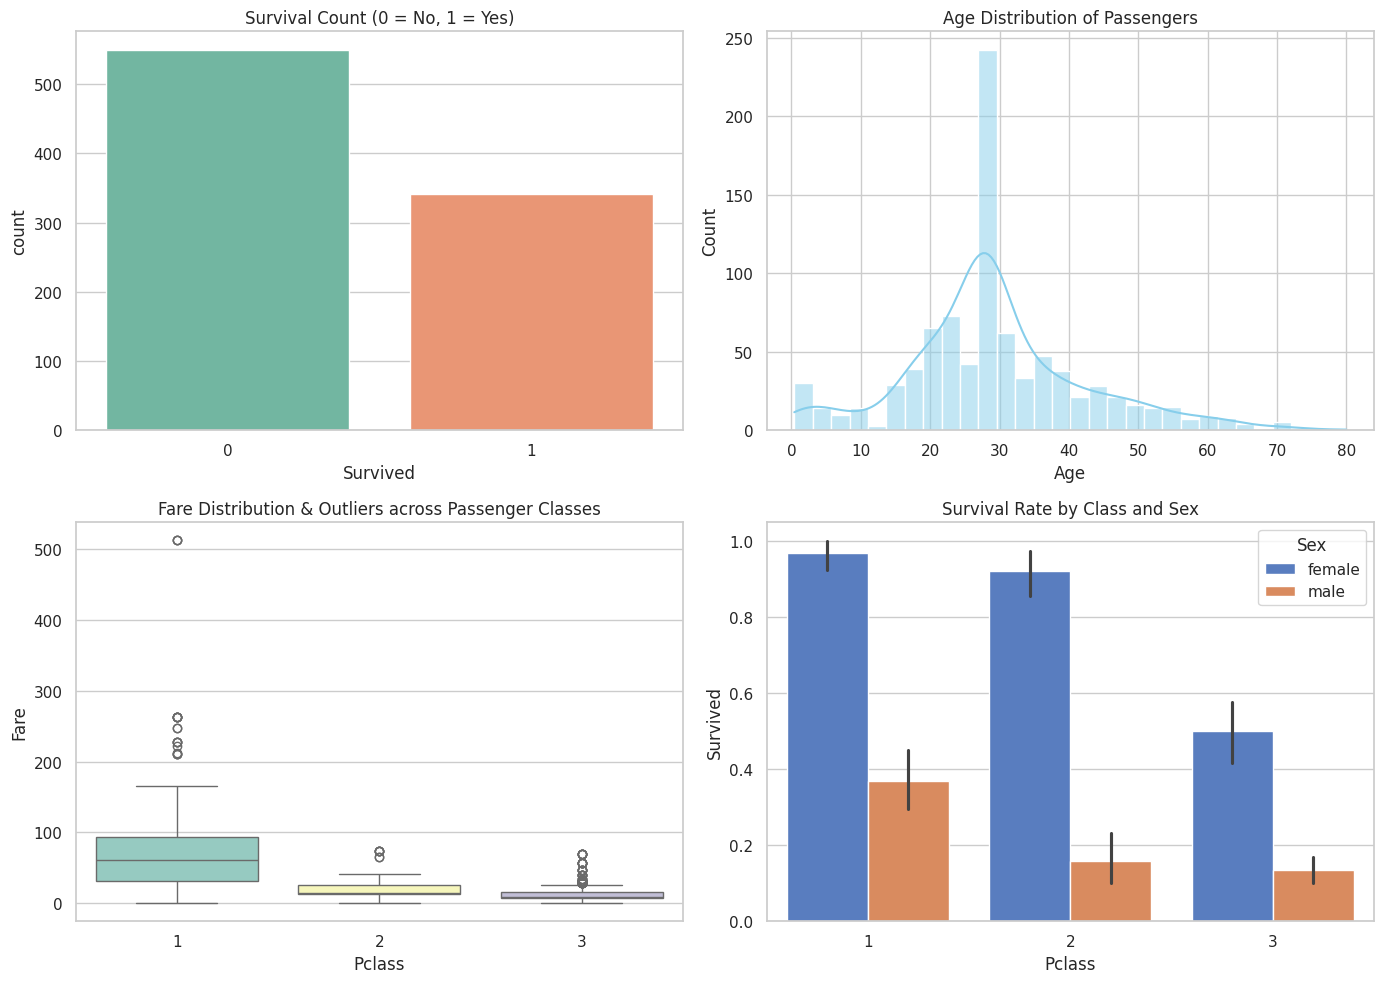

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 1. Load the raw dataset
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)

print("--- RAW DATASET OVERVIEW ---")
print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 Rows:")
print(df.head())

# 2. Check Missing Values & Data Types
print("\n--- MISSING VALUES CHECK ---")
print(df.isnull().sum())

# 3. Data Cleaning & Imputation
df['Age'].fillna(df['Age'].median(), inplace=True)
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)
df.drop(columns=['Cabin'], inplace=True)

print("\n--- AFTER CLEANING MISSING VALUES ---")
print(df.isnull().sum())

# 4. Visualizations with Seaborn
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Chart 1: Target Distribution (Survived)
sns.countplot(data=df, x='Survived', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Survival Count (0 = No, 1 = Yes)')

# Chart 2: Age Distribution
sns.histplot(data=df, x='Age', kde=True, bins=30, color='skyblue', ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution of Passengers')

# Chart 3: Outlier Detection (Fare by Passenger Class)
sns.boxplot(data=df, x='Pclass', y='Fare', palette='Set3', ax=axes[1, 0])
axes[1, 0].set_title('Fare Distribution & Outliers across Passenger Classes')

# Chart 4: Survival Rate by Sex and Pclass
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', palette='muted', ax=axes[1, 1])
axes[1, 1].set_title('Survival Rate by Class and Sex')

plt.tight_layout()
plt.savefig('task1_eda_visualizations.png', dpi=300)
plt.show()

<>:8: SyntaxWarning: invalid escape sequence '\.'
<>:8: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_8290/3288999865.py:8: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


--- NEWLY ENGINEERED FEATURES ---
                                                Name   Title  FamilySize  \
0                            Braund, Mr. Owen Harris      Mr           2   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...     Mrs           2   
2                             Heikkinen, Miss. Laina    Miss           1   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)     Mrs           2   
4                           Allen, Mr. William Henry      Mr           1   
5                                   Moran, Mr. James      Mr           1   
6                            McCarthy, Mr. Timothy J      Mr           1   
7                     Palsson, Master. Gosta Leonard  Master           5   
8  Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)     Mrs           3   
9                Nasser, Mrs. Nicholas (Adele Achem)     Mrs           2   

   IsAlone  
0        0  
1        0  
2        1  
3        0  
4        1  
5        1  
6        1  
7        0  
8        0  

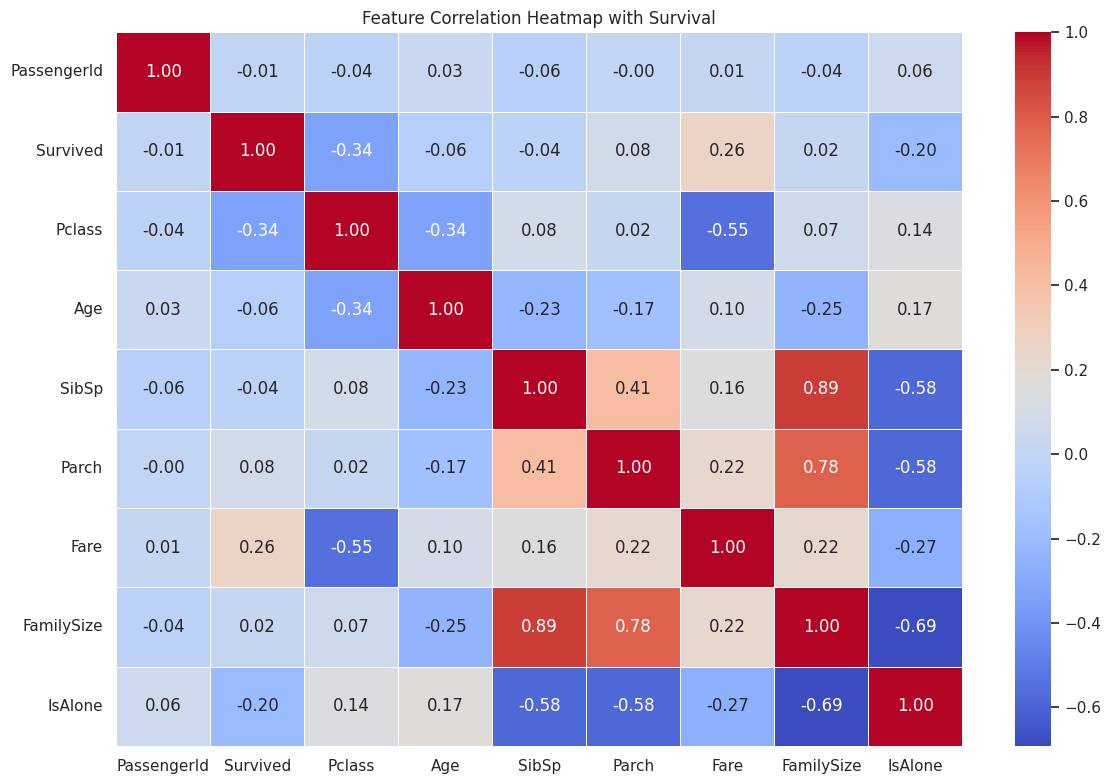


--- TOP CORRELATIONS WITH SURVIVAL ---
Survived       1.000000
Fare           0.257307
Parch          0.081629
FamilySize     0.016639
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.064910
IsAlone       -0.203367
Pclass        -0.338481
Name: Survived, dtype: float64


In [3]:
# --- TASK 2: FEATURE ENGINEERING & SELECTION ---

# 1. Feature Engineering: Create Family Dynamics Features
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# 2. Extract Titles from Name (e.g., Mr, Mrs, Miss, Master, Rare)
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
df['Title'] = df['Title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
                                   'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})

print("--- NEWLY ENGINEERED FEATURES ---")
print(df[['Name', 'Title', 'FamilySize', 'IsAlone']].head(10))

# 3. Convert Categorical Text Columns into Numbers (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['Sex', 'Embarked', 'Title'], drop_first=True)

# Drop text columns that can't be fed into mathematical models directly
df_encoded.drop(columns=['Name', 'Ticket'], inplace=True)

# 4. Feature Selection: Build a Correlation Heatmap
plt.figure(figsize=(12, 8))
numeric_df = df_encoded.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

# Plot Heatmap
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap with Survival')
plt.tight_layout()
plt.savefig('task2_correlation_matrix.png', dpi=300)
plt.show()

print("\n--- TOP CORRELATIONS WITH SURVIVAL ---")
print(correlation_matrix['Survived'].sort_values(ascending=False))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


--- MODEL PERFORMANCE COMPARISON TABLE ---
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.8045     0.7671  0.7568    0.7619   0.8865
      Decision Tree    0.8324     0.8333  0.7432    0.7857   0.8801
      Random Forest    0.8380     0.8000  0.8108    0.8054   0.8974
  Gradient Boosting    0.8212     0.8088  0.7432    0.7746   0.9077


/tmp/ipykernel_8290/534554004.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Model', y='Accuracy', palette='magma')


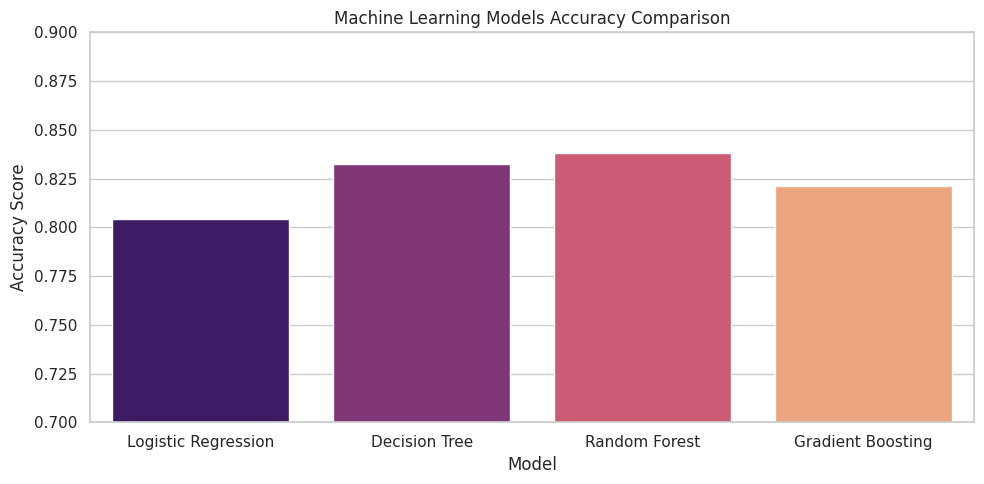

In [4]:
# --- TASK 6: MACHINE LEARNING CLASSIFICATION ---

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Define Target Variable (y) and Features (X)
X = df_encoded.drop(columns=['PassengerId', 'Survived'])
y = df_encoded['Survived']

# 2. Split Data into Training (80%) and Testing (20%) Sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize 4 Classification Algorithms
models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 4. Train Models and Evaluate Metrics
results = []

for name, model in models.items():
    # Train model
    model.fit(X_train, y_train)

    # Predict on test data
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    # Calculate performance metrics
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "F1 Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4)
    })

# Convert results into a clean table
results_df = pd.DataFrame(results)

print("--- MODEL PERFORMANCE COMPARISON TABLE ---")
print(results_df.to_string(index=False))

# 5. Plot Accuracy Comparison Bar Chart
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Model', y='Accuracy', palette='magma')
plt.title('Machine Learning Models Accuracy Comparison')
plt.ylim(0.7, 0.9)
plt.ylabel('Accuracy Score')
plt.tight_layout()
plt.savefig('task6_model_comparison.png', dpi=300)
plt.show()